**Homework 4: Evaluation Metrics for Classification**

Imports and data preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

Download and read the dataset

In [2]:
data_url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "course_lead_scoring_2026.csv"
)

df = pd.read_csv(data_url)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [4]:
print(df.dtypes)

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object


Check missing values

In [7]:
df.isnull().sum()


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

If there are missing values:
For categorical features, replace them with 'NA'
For numerical features, replace with with 0.0

In [9]:


categorical_columns = list(
    df.select_dtypes(include=["object", "str"]).columns
)

numerical_columns = list(
    df.select_dtypes(include=["number"]).columns
)


for col in categorical_columns:
    df[col] = df[col].fillna("NA")

for col in numerical_columns:
    df[col] = df[col].fillna(0.0)

df.isnull().sum().sum()


np.int64(0)

Now split the data

In [10]:

df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train["converted"].values
y_val = df_val["converted"].values

len(df_train), len(df_val), len(df_test)


(3000, 1000, 1000)

Question 1: ROC AUC feature importance


In [11]:

features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

for feature in features:
    auc = roc_auc_score(y_train, df_train[feature])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])

    print(feature, round(auc, 3))


lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


Question 2 — Train logistic regression

In [14]:

y_train = df_train["converted"].values
y_val = df_val["converted"].values

X_train_dict = df_train.drop(
    columns=["converted"]
).to_dict(orient="records")

X_val_dict = df_val.drop(
    columns=["converted"]
).to_dict(orient="records")

# one-hot encoding
dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(X_train_dict)
X_val = dv.transform(X_val_dict)

#  Fix sparse matrix
X_train.indices = X_train.indices.astype(np.int32)
X_train.indptr = X_train.indptr.astype(np.int32)

X_val.indices = X_val.indices.astype(np.int32)
X_val.indptr = X_val.indptr.astype(np.int32)

# Train logistic regression
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

# Predict probabilities on validation data
y_pred = model.predict_proba(X_val)[:, 1]

# Calculate ROC AUC
auc = roc_auc_score(y_val, y_pred)

print("Validation AUC:", round(auc, 3))


Validation AUC: 0.732


Question 3 — Precision and recall

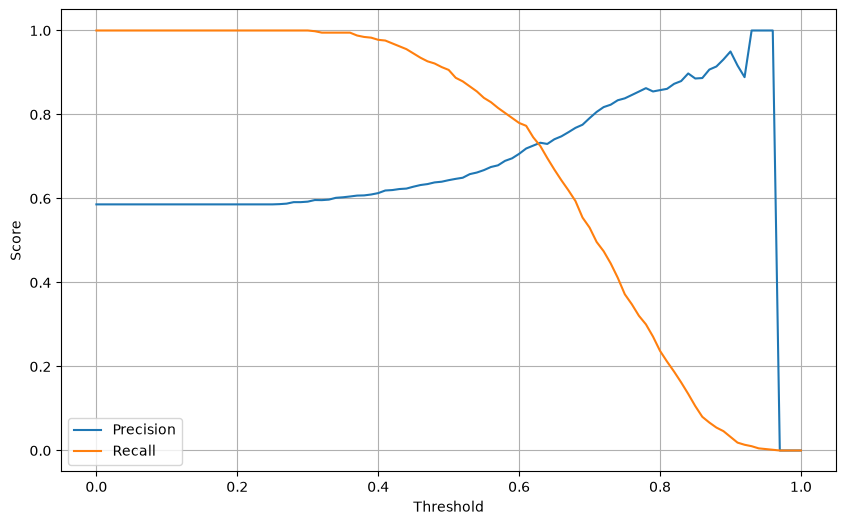

Intersection threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458


In [15]:

thresholds = np.arange(0.0, 1.01, 0.01)

precision_values = []
recall_values = []

for threshold in thresholds:
    predictions = (y_pred >= threshold).astype(int)

    precision_values.append(
        precision_score(y_val, predictions, zero_division=0)
    )
    recall_values.append(
        recall_score(y_val, predictions, zero_division=0)
    )

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision_values, label="Precision")
plt.plot(thresholds, recall_values, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

differences = np.abs(
    np.array(precision_values) - np.array(recall_values)
)

valid = (
    (np.array(precision_values) != 0)
    | (np.array(recall_values) != 0)
)

differences[~valid] = np.inf

best_index = np.argmin(differences)

print("Intersection threshold:", thresholds[best_index])
print("Precision:", precision_values[best_index])
print("Recall:", recall_values[best_index])

Question 4 — F1 score

In [16]:

precision_arr = np.array(precision_values)
recall_arr = np.array(recall_values)

denominator = precision_arr + recall_arr

f1_scores = np.divide(
    2 * precision_arr * recall_arr,
    denominator,
    out=np.zeros_like(denominator),
    where=denominator != 0
)

best_f1_index = np.argmax(f1_scores)

print("Best threshold:", thresholds[best_f1_index])
print("Maximum F1:", round(f1_scores[best_f1_index], 3))


Best threshold: 0.41000000000000003
Maximum F1: 0.758


Question 5 — 5-Fold cross-validation

In [26]:

def train_and_evaluate(train_df, val_df, C=1.0):
    y_train_fold = train_df["converted"].values
    y_val_fold = val_df["converted"].values

    train_dict = train_df.drop(
        columns=["converted"]
    ).to_dict(orient="records")

    val_dict = val_df.drop(
        columns=["converted"]
    ).to_dict(orient="records")

    dv = DictVectorizer(sparse=True)

    X_train_fold = dv.fit_transform(train_dict).tocsr()
    X_val_fold = dv.transform(val_dict).tocsr()

    # Fix sparse matrix index compatibility
    for X in [X_train_fold, X_val_fold]:
        X.indices = X.indices.astype(np.int32)
        X.indptr = X.indptr.astype(np.int32)

    model = LogisticRegression(
        solver="liblinear",
        C=C,
        max_iter=1000
    )

    model.fit(X_train_fold, y_train_fold)

    y_pred_fold = model.predict_proba(X_val_fold)[:, 1]

    return roc_auc_score(y_val_fold, y_pred_fold)


In [27]:

from sklearn.model_selection import KFold
import numpy as np

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    train_fold = df_full_train.iloc[train_idx]
    val_fold = df_full_train.iloc[val_idx]

    score = train_and_evaluate(train_fold, val_fold)
    scores.append(score)

print("Fold scores:", scores)
print("Mean AUC:", round(np.mean(scores), 3))
print("Standard deviation:", round(np.std(scores), 3))


Fold scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.732
Standard deviation: 0.007


Question 6 — Hyperparameter tuning

In [28]:

C_values = [0.000001, 0.001, 1]

for C in C_values:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        train_fold = df_full_train.iloc[train_idx]
        val_fold = df_full_train.iloc[val_idx]

        score = train_and_evaluate(
            train_fold,
            val_fold,
            C=C
        )

        scores.append(score)

    print(
        f"C={C}: "
        f"mean={np.mean(scores):.3f}, "
        f"std={np.std(scores):.3f}"
    )


C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.749, std=0.010
C=1: mean=0.732, std=0.007
